# Defined-benefit pension analysis

**Northwind Components Pension Plan**, a fictional ongoing final-average-pay plan, measured at December 31, 2025.

This notebook is the working file behind the portfolio project. It builds a seeded synthetic census, scrubs it the way a pension risk transfer desk scrubs a tape, and values the plan life by life. The model code is in `src/pension`. Every dollar below is computed in this run.

The census is synthetic. The mortality tables and the discount curve are public. Nothing here is actuarial advice, a buyout quote, or the experience of any insurer or plan sponsor, including Group 1001 and American National.

## The question

A sponsor with an open defined-benefit plan has three numbers in front of it: the accounting liability, the assets, and a market for transferring the promises to an insurer.

The practical questions, before anyone requests a quote, are:

1. Do the participant records support a price?
2. What is the projected benefit obligation, and how much of it is already accrued?
3. How does funded status move when the discount curve moves?
4. What happens to the remaining plan if only retirees are lifted out, compared with buying annuities for everyone?

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from pension.analysis import run
from pension.assumptions import Assumptions
from pension.cashflows import life_annuity_factor
from pension.discount import DiscountCurve
from pension.mortality import build_mortality
from pension.reporting import money, percent

assumptions = Assumptions()
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
pd.set_option("display.max_colwidth", 120)
print(assumptions.plan_name)
print("Measurement date", assumptions.measurement_date.isoformat())
print("Stated assets", money(assumptions.market_value_of_assets))
print("Seed", assumptions.seed)

Northwind Components Pension Plan
Measurement date 2025-12-31
Stated assets $200,000,000
Seed 1001


## Run the measurement

`run` generates the census, applies the data checks, projects monthly cash flows, discounts them on the Treasury HQM curve, prices the two transaction structures, and writes the charts and the workbook. The asset value and the pricing loads are arguments, fixed before this cell knows the liability.

In [2]:
results = run(assumptions)
liability = results["liability"]
prt = results["prt"]

Northwind Components Pension Plan 2025-12-31
Clean lives 1563 of 1580
ABO 223,036,093.95   PBO 262,950,594.69
Funded ratio 76.06%   effective rate 5.70%   duration 13.89
Lift-out premium 126,850,139.06   termination premium 258,000,058.95


## Census and the tape scrub

The generator draws actives, deferred vested participants, retirees, and beneficiaries from a fixed seed, then plants a short list of bad records. Hard findings leave the valuation. Soft findings stay in and are reported, which is what a pricing analyst does with a tolerable exception.

In [3]:
raw = pd.read_csv(ROOT / "data/output/census_raw.csv")
clean = pd.read_csv(ROOT / "data/output/census_clean.csv")
findings = pd.read_csv(ROOT / "data/output/validation_findings.csv")
print(f"Raw records {len(raw):,}    clean records {len(clean):,}    excluded {len(raw) - len(clean):,}")
display(clean.groupby("status").agg(lives=("participant_id", "size"), annual_benefit=("annual_benefit", "sum"), average_age=("age", "mean")))
print("Findings by rule")
display(findings.groupby(["severity", "rule_id"]).size().rename("findings").reset_index())

Raw records 1,580    clean records 1,563    excluded 17


,lives,annual_benefit,average_age
status,,,
active,514,"11,896,084.55",47.53
beneficiary,109,"1,081,493.04",81.36
deferred_vested,306,"5,358,725.70",53.33
retiree,634,"11,306,704.86",76.63


Findings by rule


,severity,rule_id,findings
0,hard,bad_age,1
1,hard,bad_benefit,3
2,hard,bad_compensation,1
3,hard,bad_final_average_pay,1
4,hard,bad_sex,3
5,hard,duplicate_id,2
6,hard,hire_after_measurement,1
7,hard,impossible_service,2
8,hard,joint_missing_spouse,1
9,hard,retiree_too_young,1


The same tape is loaded into SQLite so the row counts can be checked in SQL. The queries live in `src/pension/sql/census_checks.sql`.

In [4]:
duplicates = pd.read_csv(ROOT / "data/output/sql_duplicate_ids.csv")
missing_spouse = pd.read_csv(ROOT / "data/output/sql_joint_life_missing_spouse.csv")
outliers = pd.read_csv(ROOT / "data/output/sql_formula_outliers.csv")
display(duplicates)
display(missing_spouse)
display(outliers)

,participant_id,rows_with_this_id
0,R-0001,2


,participant_id,status,payment_form,spouse_date_of_birth,spouse_sex
0,R-0004,retiree,JS100,NaN,NaN


,participant_id,age,service_years,final_average_pay,annual_benefit,implied_accrual_rate
0,A-0004,40.00,40.00,"100,534.17","19,604.16",0.00
1,A-0007,41.00,16.00,"73,892.88","26,601.44",0.02


## Liability

Benefits are projected one participant at a time. Actives retire at the earliest unreduced age (62 with 30 years of service, otherwise 65). The ABO uses the accrued life annuity. The PBO, on the projected unit credit method, grows final average pay at 3.5% and recognizes the unreduced 30-and-out subsidy. In-pay benefits are the payment already on the tape, so ABO and PBO match for retirees and beneficiaries.

Discount rates are the Treasury High Quality Market corporate spot curve at December 31, 2025, semiannually compounded. Mortality is Pri-2012 amount-weighted total dataset, projected generationally with Scale MP-2021.

In [5]:
print("ABO", money(liability["abo"], 2))
print("PBO", money(liability["pbo"], 2))
print("PBO minus ABO", money(liability["pbo_minus_abo"], 2))
print("Assets", money(liability["assets"]))
print("Deficit", money(-liability["surplus"], 2))
print("Funded ratio on PBO", percent(liability["funded_ratio"], 2))
print("Single effective rate", percent(liability["effective_annual_rate"], 2))
print("Effective duration", f"{liability['effective_duration']:.2f} years")
print("Average payment time", f"{liability['average_payment_time']:.2f} years")
print("DV01", money(liability["dv01"], 2))
status = pd.DataFrame(results["by_status"])
display(status)

ABO $223,036,093.95
PBO $262,950,594.69
PBO minus ABO $39,914,500.74
Assets $200,000,000
Deficit $62,950,594.69
Funded ratio on PBO 76.06%
Single effective rate 5.70%
Effective duration 13.89 years
Average payment time 14.14 years
DV01 $361,758.55


,status,participants,average_age,pbo_weighted_age,tape_annual_benefit,abo_annual_benefit,pbo_annual_benefit,abo,pbo
0,active,514,47.53,51.85,"11,896,084.55","10,665,397.18","18,235,704.81","74,169,472.74","114,083,973.48"
1,deferred_vested,306,53.33,55.46,"5,358,725.70","5,358,725.70","5,358,725.70","36,341,557.79","36,341,557.79"
2,retiree,634,76.63,74.94,"11,306,704.86","11,306,704.86","11,306,704.86","104,713,663.51","104,713,663.51"
3,beneficiary,109,81.36,79.20,"1,081,493.04","1,081,493.04","1,081,493.04","7,811,399.91","7,811,399.91"


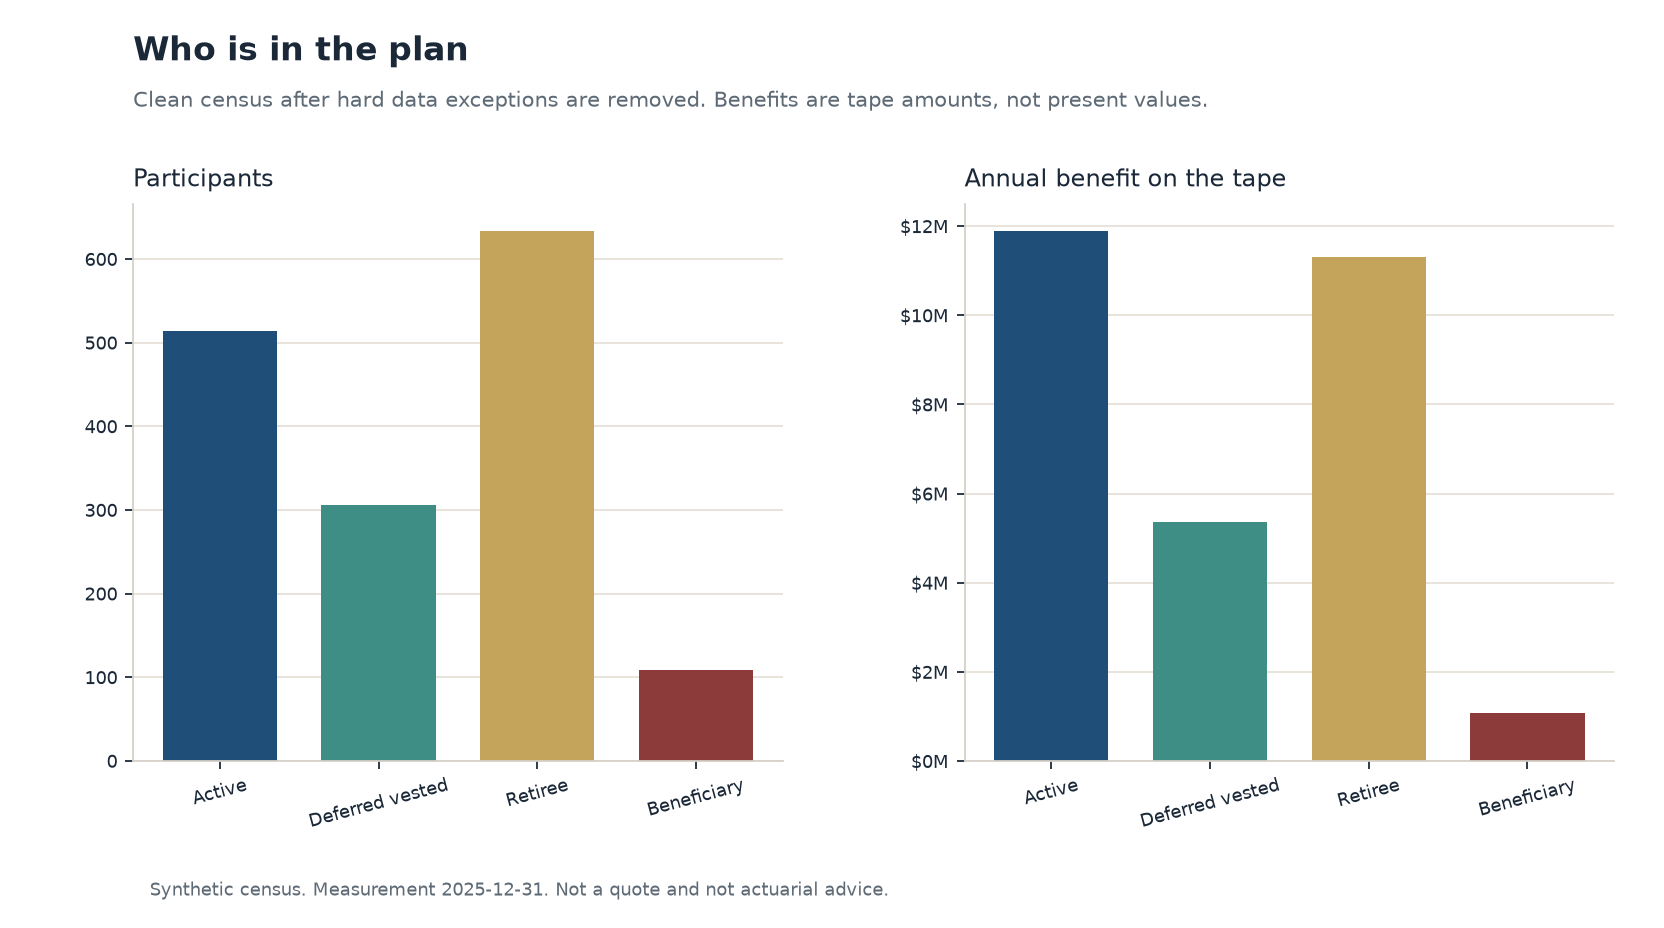

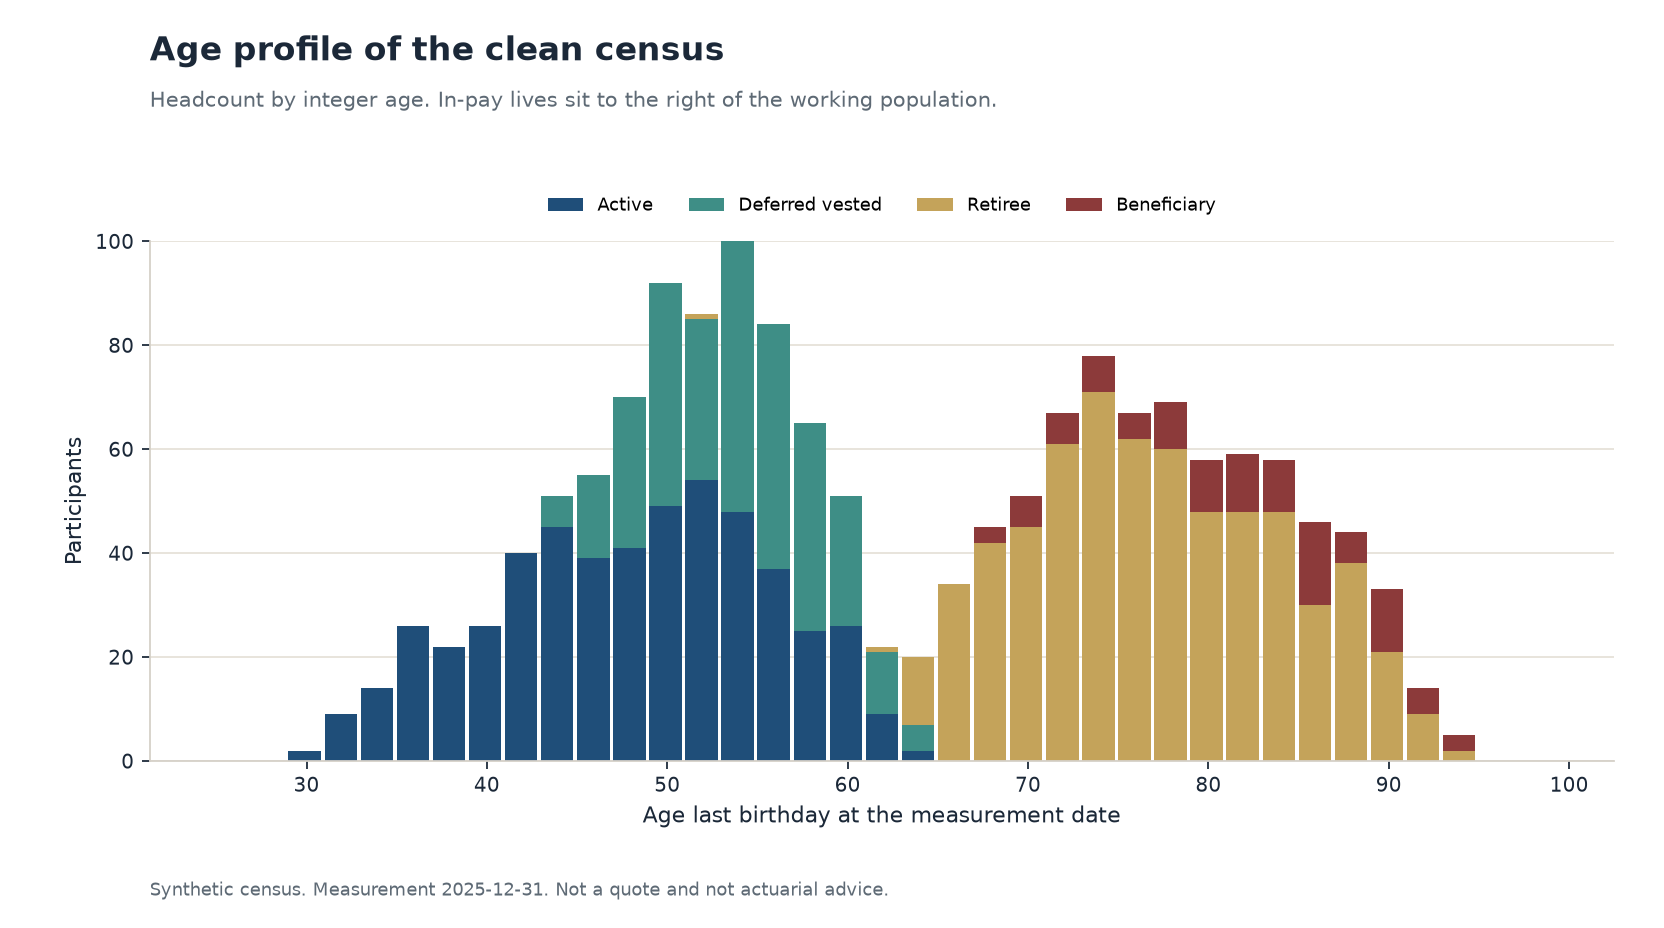

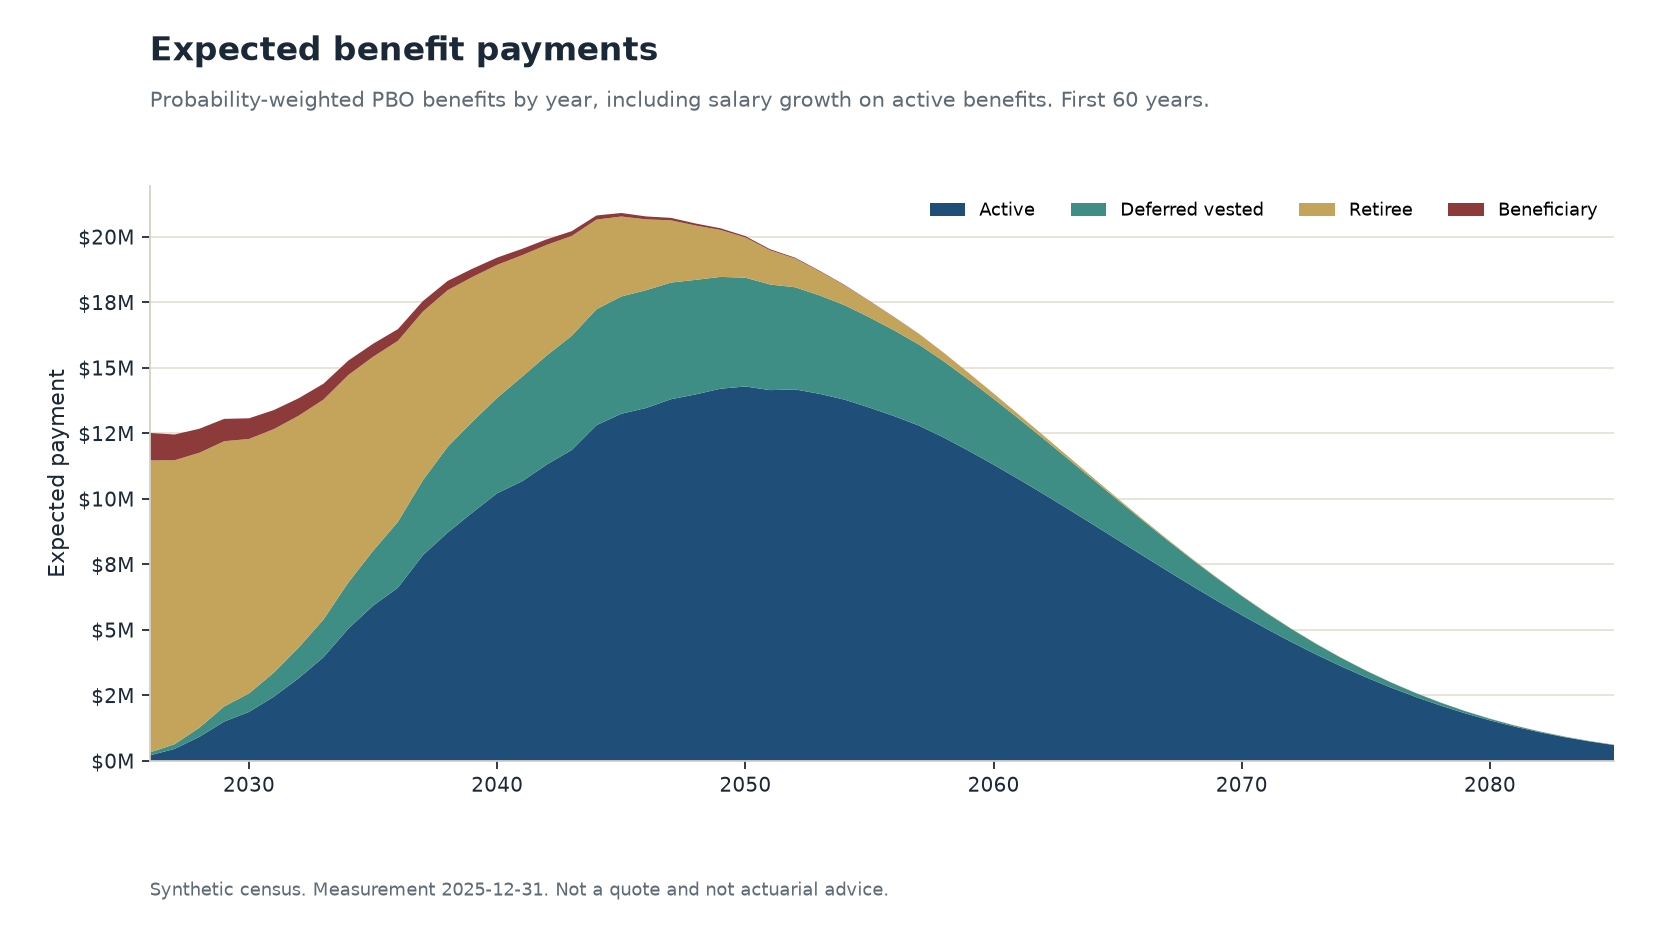

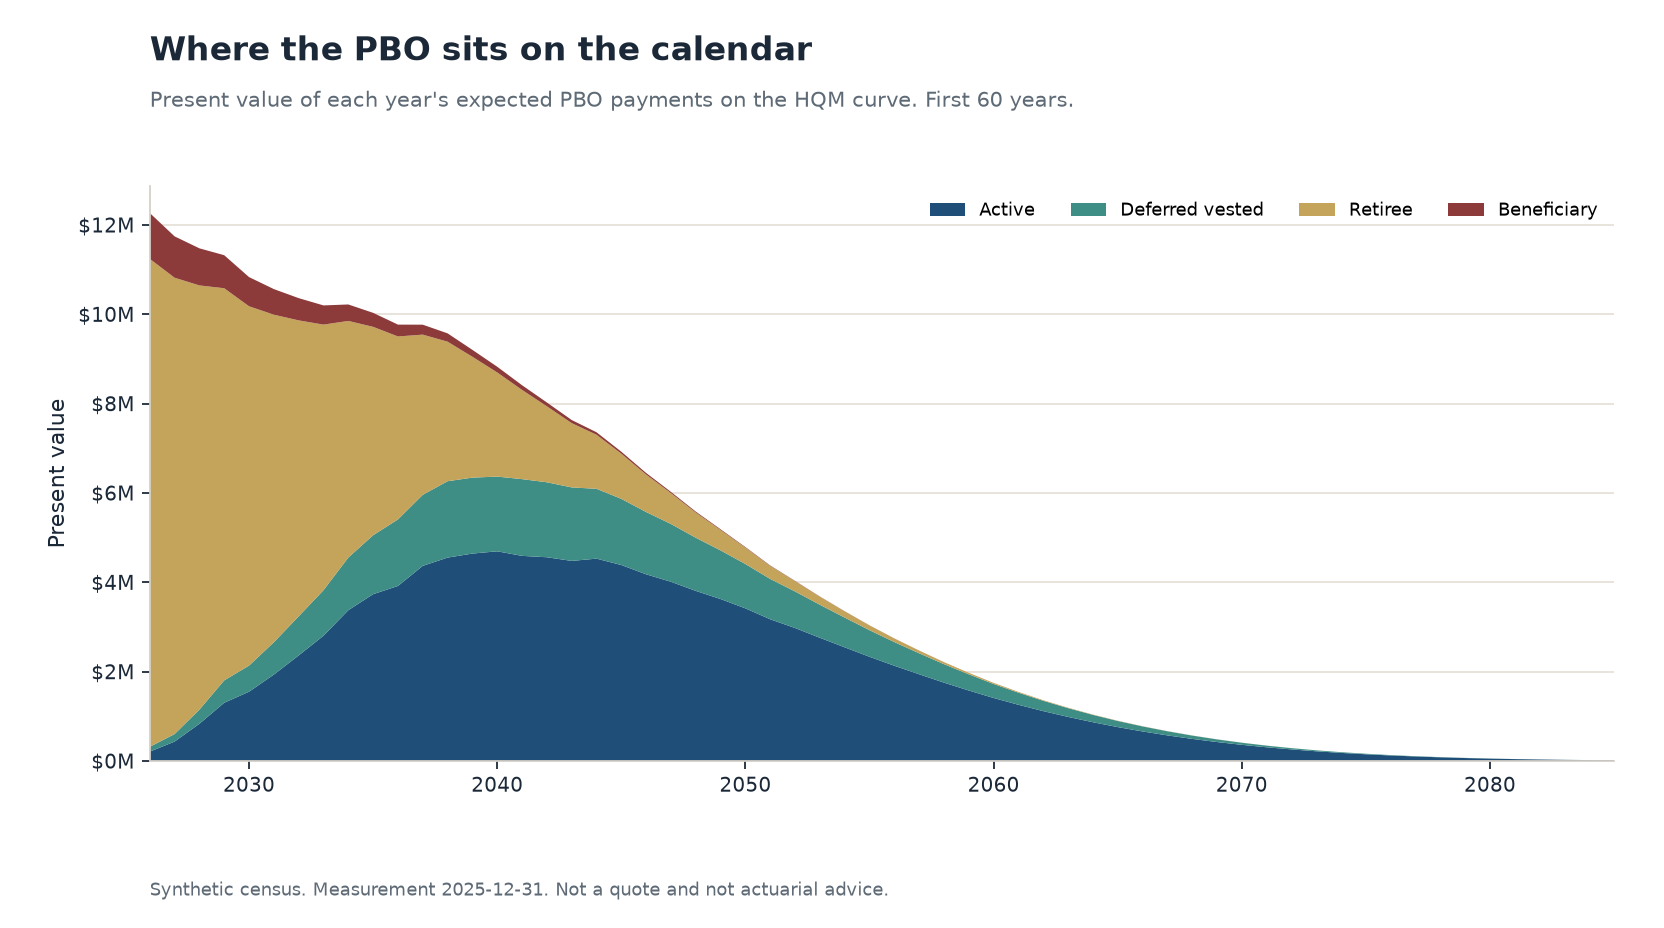

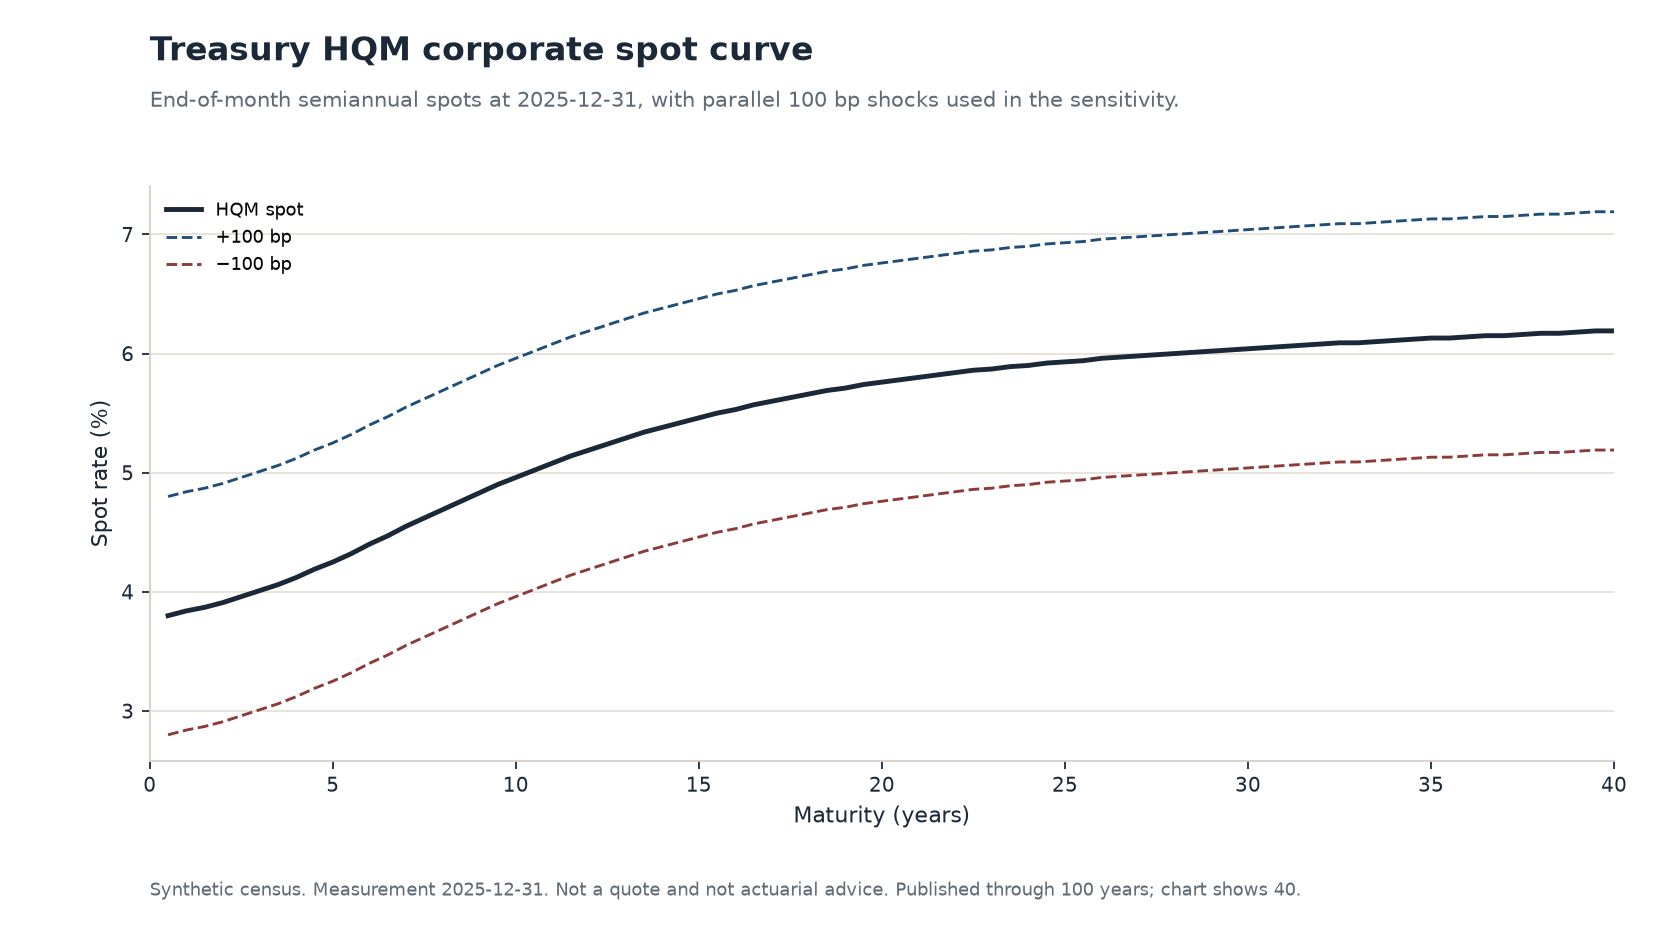

In [6]:
for name in [
    "census_composition.png",
    "age_distribution.png",
    "projected_cash_flows.png",
    "present_value_profile.png",
    "discount_curve.png",
]:
    display(Image(filename=str(ROOT / "reports/figures" / name)))

## A check against the published SOA factors

Scale MP-2021's report publishes monthly deferred-to-62 annuity-due factors at 4% as of January 1, 2021. The factor routine uses the same base table, the same scale, and the same employee/retiree split. This cell reprints two of those ages; the unit tests cover the full published grid and require agreement within 0.12%.

In [7]:
published = {("F", 65): 14.2572, ("M", 65): 13.3798, ("F", 45): 7.9383, ("M", 45): 7.4405}
curve = DiscountCurve.flat_annual_effective(0.04)
mortality = build_mortality()
rows = []
for (sex, age), target in published.items():
    modeled = life_annuity_factor(mortality, sex, age, 2021, curve, due=True, defer_to_age=62)
    rows.append({
        "sex": sex,
        "age": age,
        "modeled": f"{modeled:.4f}",
        "published": f"{target:.4f}",
        "difference": f"{(modeled / target - 1) * 100:+.2f}%",
    })
display(pd.DataFrame(rows))


,sex,age,modeled,published,difference
0,F,65,14.2585,14.2572,+0.01%
1,M,65,13.3860,13.3798,+0.05%
2,F,45,7.9323,7.9383,-0.07%
3,M,45,7.4355,7.4405,-0.07%


## Interest rates and mortality

The cash flows stay put in the rate scenarios. Only the spot curve moves, in a parallel shift. The mortality scenarios rebuild the cash flows: one with improvement frozen at the 2026 rate, and one with an extra 50 basis points of improvement each year from 2026 forward.

,shock_bp,pbo,funded_ratio,surplus
0,-100,"303,391,010.24",65.9%,"-103,391,010.24"
1,-50,"282,055,325.27",70.9%,"-82,055,325.27"
2,0,"262,950,594.69",76.1%,"-62,950,594.69"
3,50,"245,791,972.19",81.4%,"-45,791,972.19"
4,100,"230,336,164.65",86.8%,"-30,336,164.65"


,label,pbo,change_vs_base
0,No future improvement,"255,651,751.91",-2.8%
1,MP-2021 generational,"262,950,594.69",+0.0%
2,MP-2021 +50 bp,"267,382,067.62",+1.7%


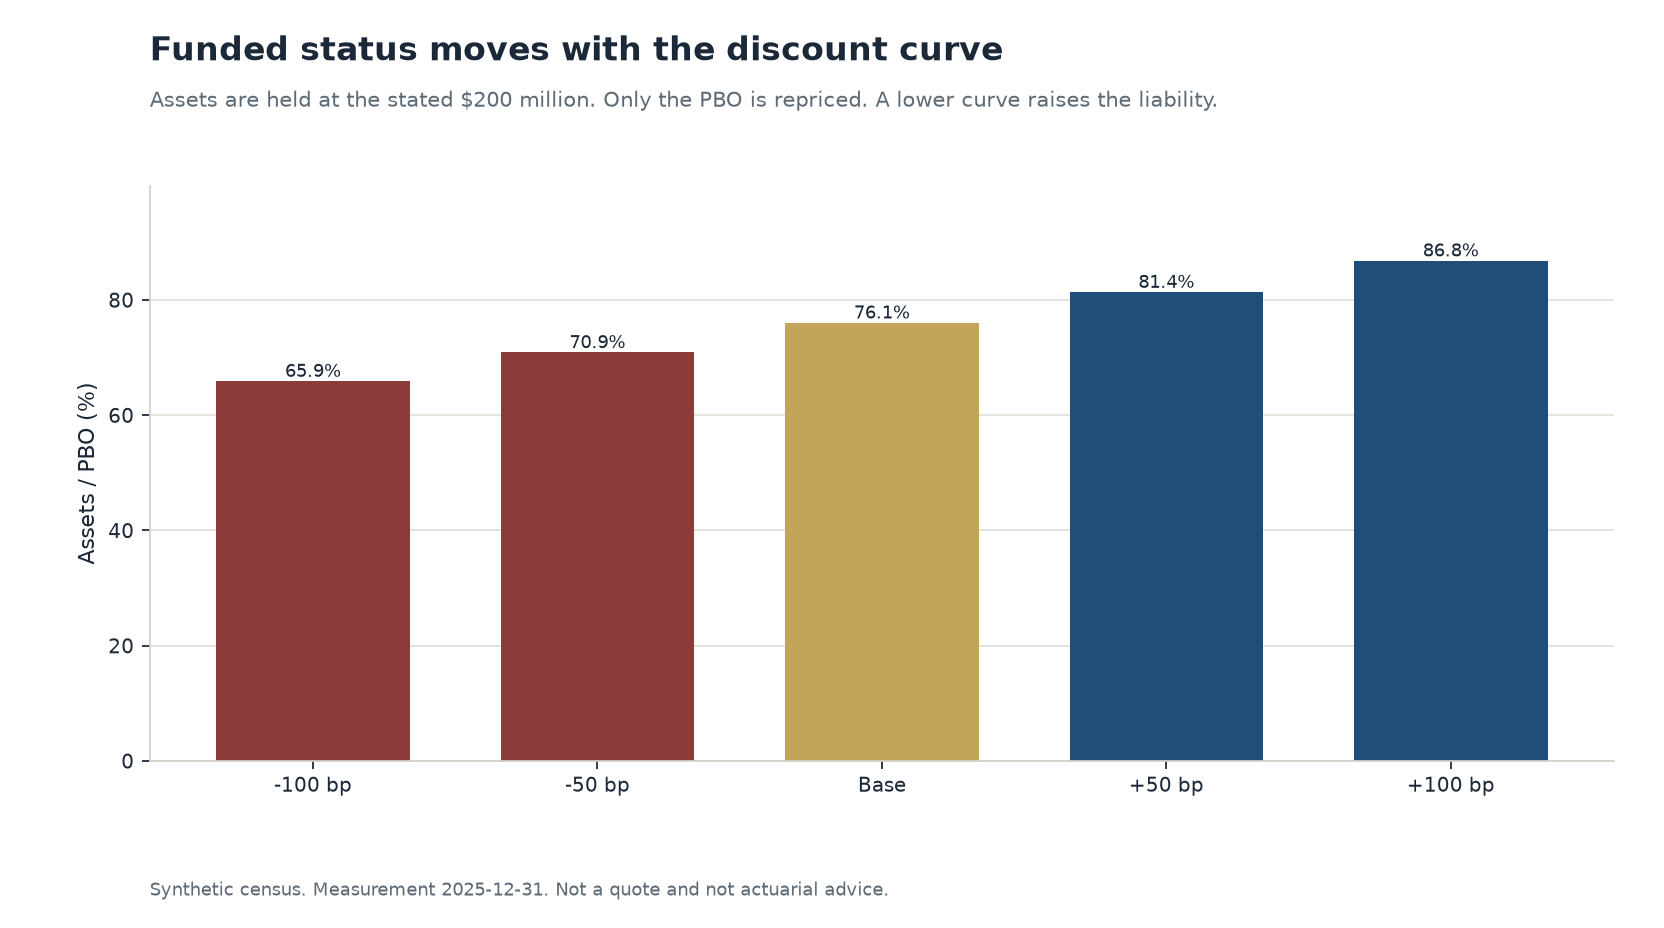

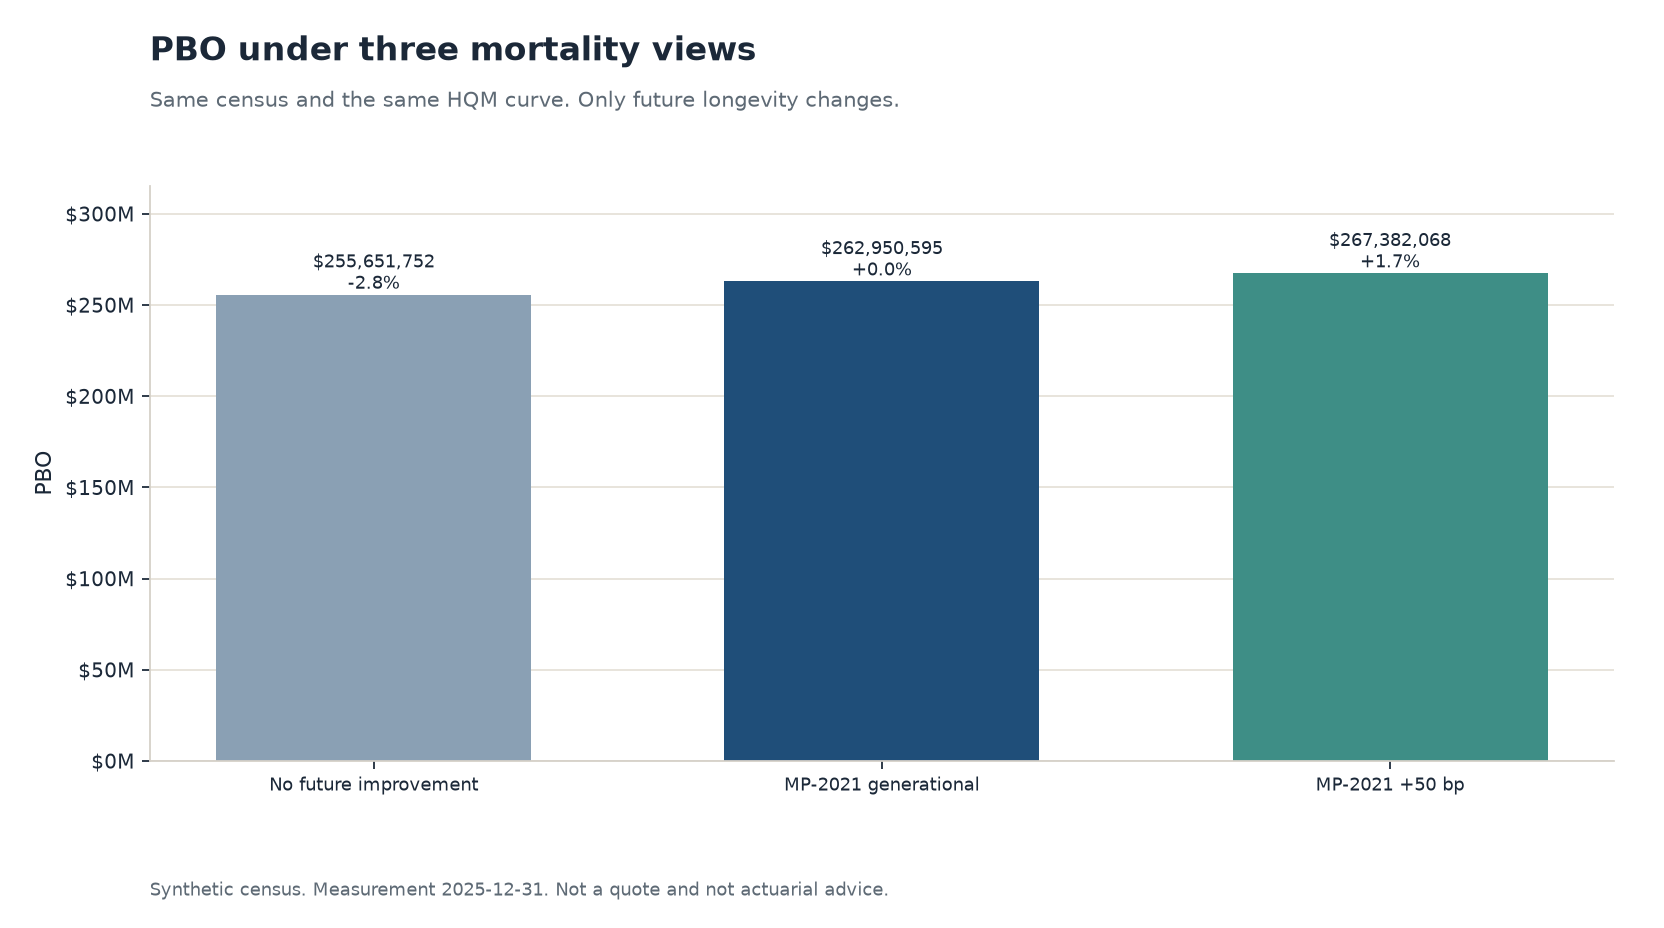

In [8]:
rates = pd.DataFrame(results["rate_scenarios"])
rates["funded_ratio"] = rates["funded_ratio"].map(lambda value: f"{value * 100:.1f}%")
display(rates)
mortality_view = pd.DataFrame(results["mortality_scenarios"])
mortality_view["change_vs_base"] = mortality_view["change_vs_base"].map(lambda value: f"{value * 100:+.1f}%")
display(mortality_view)
for name in ["funded_status_by_rates.png", "mortality_sensitivity.png"]:
    display(Image(filename=str(ROOT / "reports/figures" / name)))

## Pension risk transfer

The indication prices the same engine on a stricter basis: mortality rates multiplied by 0.90, the HQM curve 50 basis points lower, $240 a year of expenses while the contract is in force, and a 3.5% load on premium.

A retiree lift-out buys the in-pay annuities only. A termination curtails future salary growth, then buys the accrued benefit for every remaining record. The cash shortfall is the contribution required when the premium exceeds the stated assets.

,,Retiree lift-out,Full termination
0,Lives transferred,743,1563
1,Accounting liability released,"$112,525,063.42","$223,036,093.95"
2,Illustrative premium,"$126,850,139.06","$258,000,058.95"
3,Premium versus that liability,12.73%,15.68%
4,Settlement loss,"$14,325,075.64","$34,963,964.99"
5,Cash shortfall versus assets,$0.00,"$58,000,058.95"


Residual assets after the lift-out $73,149,860.94
Residual PBO $150,425,531.27
Residual funded ratio 48.63%
Curtailment gain if the plan terminates $39,914,500.74
Termination premium versus the pre-termination PBO -$4,950,535.74


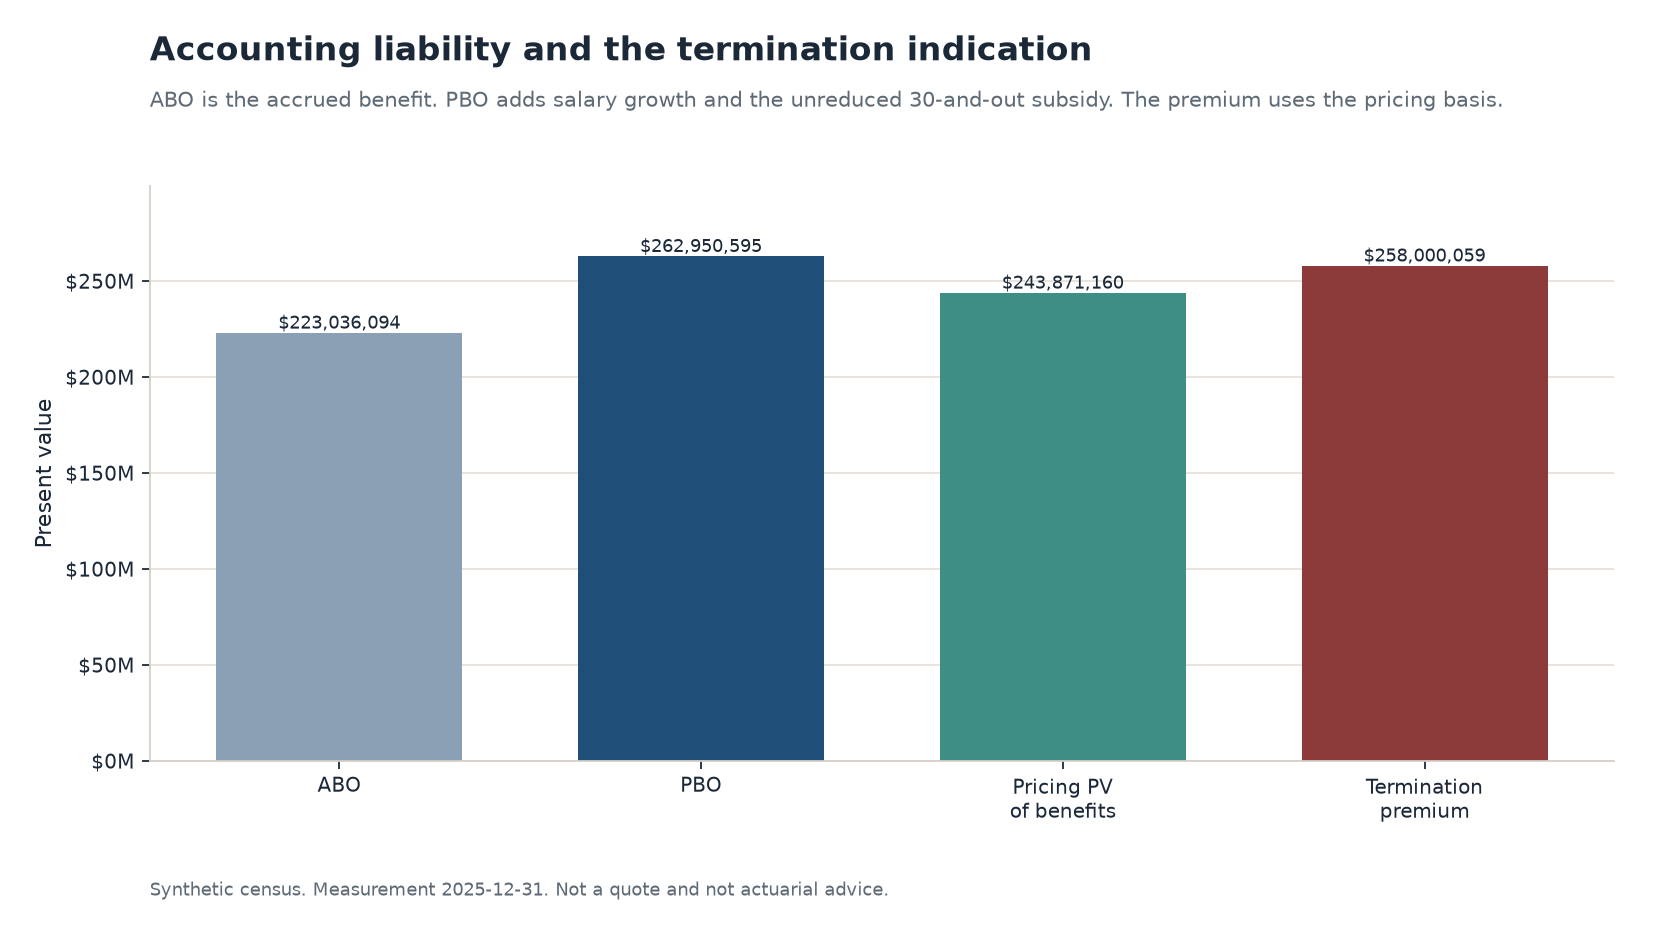

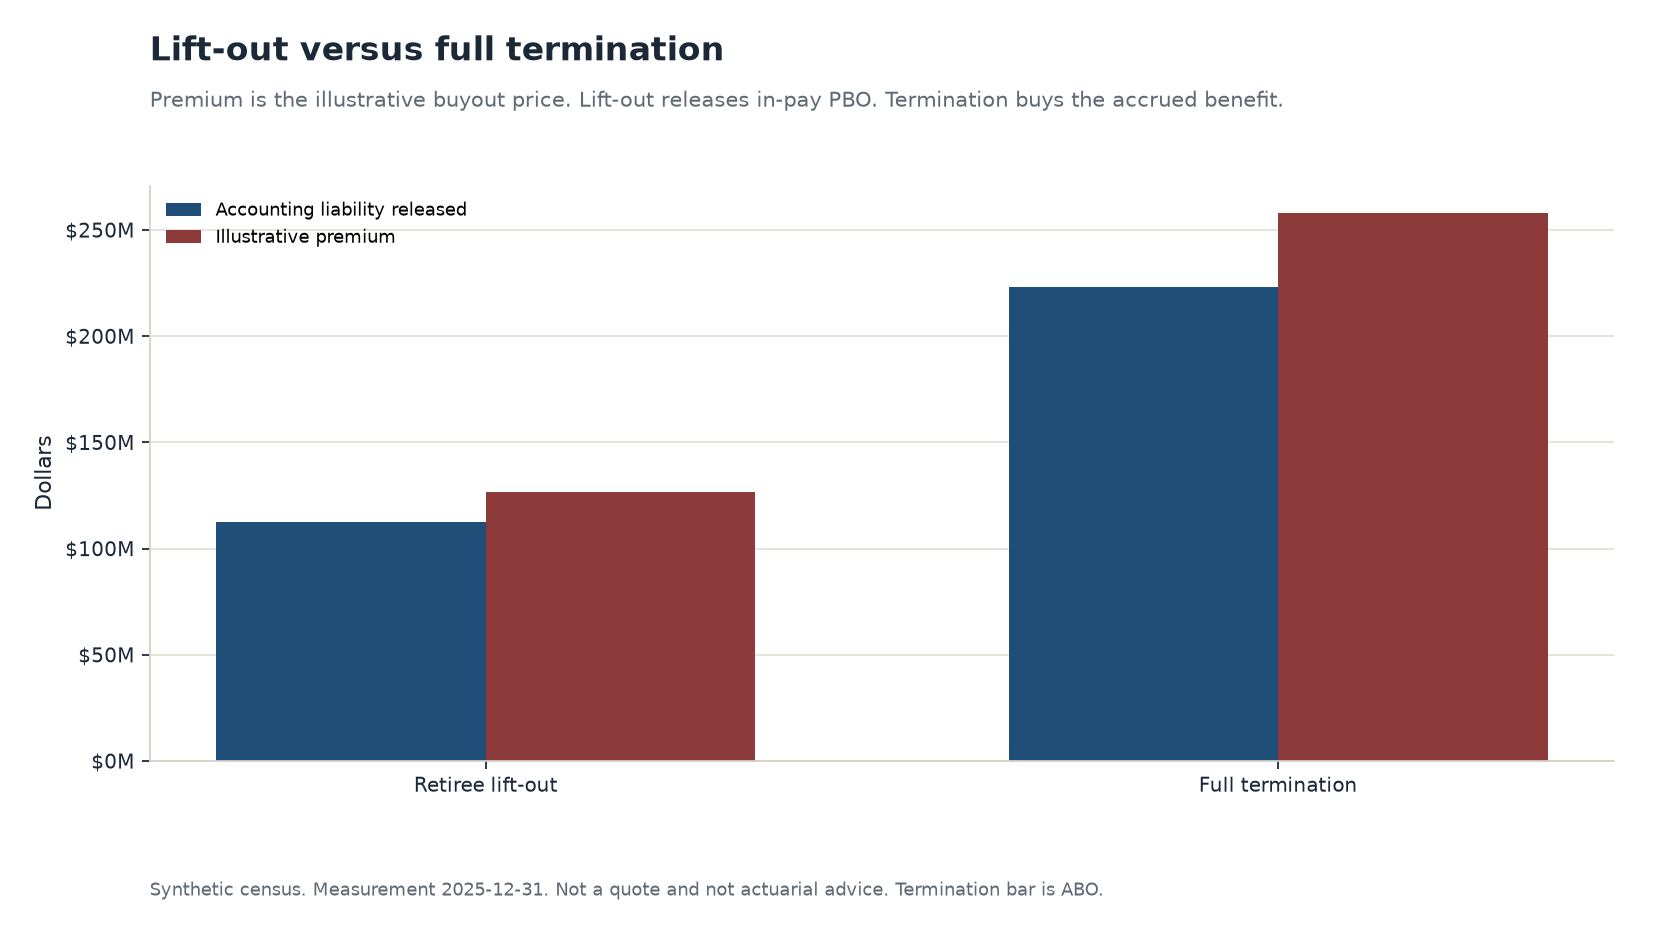

In [9]:
rows = [
    ("Lives transferred", f"{prt['liftout_lives']:.0f}", f"{prt['termination_lives']:.0f}"),
    ("Accounting liability released", money(prt["liftout_pbo_released"], 2), money(prt["termination_abo"], 2)),
    ("Illustrative premium", money(prt["liftout_premium"], 2), money(prt["termination_premium"], 2)),
    ("Premium versus that liability", percent(prt["liftout_premium_over_pbo"], 2), percent(prt["termination_premium_over_abo"], 2)),
    ("Settlement loss", money(prt["liftout_settlement_loss"], 2), money(prt["termination_settlement_loss"], 2)),
    ("Cash shortfall versus assets", money(prt["liftout_cash_shortfall"], 2), money(prt["termination_cash_shortfall"], 2)),
]
comparison = pd.DataFrame(rows, columns=["", "Retiree lift-out", "Full termination"])
display(comparison)
print("Residual assets after the lift-out", money(prt["residual_assets"], 2))
print("Residual PBO", money(prt["residual_pbo"], 2))
print("Residual funded ratio", percent(prt["residual_funded_ratio"], 2))
print("Curtailment gain if the plan terminates", money(prt["curtailment_gain"], 2))
print("Termination premium versus the pre-termination PBO", money(prt["termination_net_accounting_cost"], 2))
display(Image(filename=str(ROOT / "reports/figures/liability_comparison.png")))
display(Image(filename=str(ROOT / "reports/figures/prt_liftout_vs_termination.png")))

## Reading the two transactions

The lift-out premium is above the in-pay PBO, and it is paid from plan assets. What remains is the active and deferred liability, with fewer assets. Funded status of the ongoing plan falls even though the transaction itself fits inside the asset balance.

The termination premium is above the ABO, which is the benefit an insurer would be buying. It is below the pre-termination PBO, because terminating the plan removes the salary-growth piece of the PBO (the curtailment) and that removal is larger than the premium loading on the accrued benefit. The sponsor still writes a check: the premium is larger than the assets. The accounting comparison and the cash contribution are different numbers, and both belong in the discussion.